### Part 1

In [47]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from matplotlib.colors import AsinhNorm

# Allow running from either the notebook folder or the repository root.
pset4_path = Path('.') if Path('P4_flats').is_dir() else Path('pset4')
twilight_frames = sorted((pset4_path / 'P4_flats' / 'twilight').glob('twilight_*.fits'))
twilight_data = [fits.getdata(path).astype(float) for path in twilight_frames]
twilight_times = np.array([fits.getheader(path)['EXPTIME'] for path in twilight_frames])


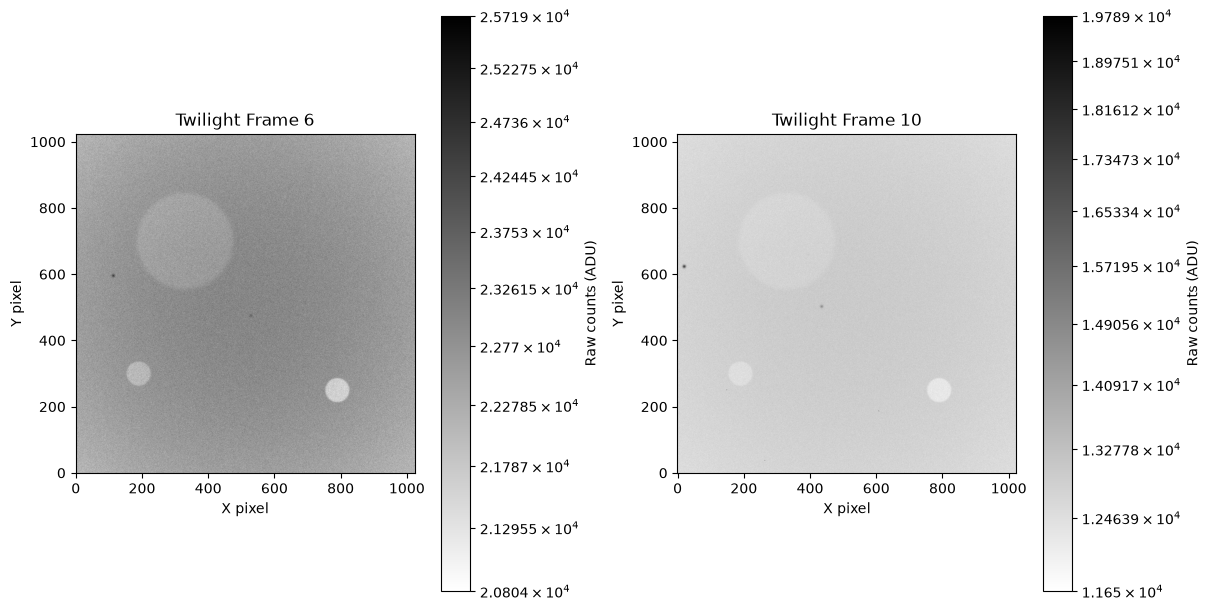

In [48]:
# Display frames 6 and 10
fig, axs = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
for ax, i in zip(axs, [5, 9]):
    image = ax.imshow(twilight_data[i], origin='lower', cmap='gray_r', norm=AsinhNorm())
    ax.set_title(f'Twilight Frame {i + 1}')
    ax.set_xlabel('X pixel')
    ax.set_ylabel('Y pixel')
    fig.colorbar(image, ax=ax, label='Raw counts (ADU)')
plt.show()


#### Written 1.1

Besides the sky and what are presumably some stars in the sky (the two black dots above), we have some large blobs that are actually lighter than the rest of the image, indicating that it's probably something blocking out light in that area.

We need to move around the telescope because then we're able to distinguish the two following reasons why we have different light in different areas when we median combine the flats: stars (whose impact we wish to nullify), and dust particles/other features of the setup (which won't move if we point the telescope to slightly different areas of the sky).

In [49]:
# Pset 3, 2.4: last sampled point within 1% gives a raw ceiling of 41742 ADU.
linearity_limit = 41742  # raw ADU, including bias
keep = np.array([np.max(frame) < linearity_limit for frame in twilight_data])

# Check peak pixels against the ceiling; also report each raw median.
print(f'Linearity ceiling: below {linearity_limit} raw ADU')
print('Frame              Time (s)   Median (ADU)   Peak (ADU)   Decision')
for path, time, frame, good in zip(twilight_frames, twilight_times, twilight_data, keep):
    print(f"{path.name:18s} {time:7.1f} {np.median(frame):14.1f} "
          f"{np.max(frame):12.1f}   {'keep' if good else 'reject'}")


Linearity ceiling: below 41742 raw ADU
Frame              Time (s)   Median (ADU)   Peak (ADU)   Decision
twilight_01.fits       1.0        43795.0      47146.0   reject
twilight_02.fits       1.3        34995.0      40037.0   keep
twilight_03.fits       1.7        31710.0      33636.0   keep
twilight_04.fits       2.2        28425.0      34222.0   keep
twilight_05.fits       2.8        25550.0      32897.0   keep
twilight_06.fits       3.6        22675.0      25719.0   keep
twilight_07.fits       4.6        20212.0      26208.0   keep
twilight_08.fits       5.8        17748.0      20805.0   keep
twilight_09.fits       7.4        15283.0      20521.0   keep
twilight_10.fits       9.4        12820.0      19789.0   keep


#### Written 1.2

The median level of each frame varies between 43795 and 12820 (as seen in the table above). We reject only the first flat because its peak of 47146 ADU exceeds our linearity ceiling (41742 raw ADU); its median also exceeds this ceiling. We keep the rest of the frames.

#### Written 1.3

Once the ADU passes the ``linearity ceiling`` we determined in the previous problem set, the measured response is sublinear: additional electrons produce less additional ADU than in the linear regime. In particular, the brightest portions of the flat (the middle of it) are the most affected by this nonlinearity since they are the farthest above the linearity threshold. Their response is compressed relative to the darker edges, so the shape of the flat changes; dividing by a single median cannot correct this spatial distortion.


### Part 2

In [50]:
# Rebuild the Pset 3 calibration maps so this notebook runs on its own.
calib_path = pset4_path.resolve().parent / 'pset3' / 'P3_calib'
bias_frames = [fits.getdata(path).astype(float)
               for path in sorted((calib_path / 'bias').glob('bias_*.fits'))]
master_bias_frame = np.median(bias_frames, axis=0)

dark_paths = sorted((calib_path / 'dark').glob('dark_*.fits'))
long_darks = [fits.getdata(path).astype(float) for path in dark_paths
              if fits.getheader(path)['EXPTIME'] == 600]
dark_rate = (np.mean(long_darks, axis=0) - master_bias_frame) / 600  # ADU/s
bad_pixel_mask = dark_rate > 10 * np.median(dark_rate)  # same mask as Pset 3

# Calibration here means bias subtraction, exposure-scaled dark subtraction,
# and bad-pixel masking. Do not divide by a flat: these frames will make the flat.
gain = 1.20

def calibrate(raw, exptime, master_bias, dark_rate, gain):
    return (np.asarray(raw, dtype=float) - master_bias) * gain - dark_rate * exptime

def calibrate_twilight(frame, exposure_time):
    return np.ma.array(calibrate(frame, exposure_time, master_bias_frame, dark_rate * gain, gain),
                       mask=bad_pixel_mask)

def master_flat(paths, master_bias, dark_rate, gain, bad_pixels, method='median'):
    frames = [np.ma.array(calibrate(fits.getdata(path), fits.getheader(path)['EXPTIME'],
                                   master_bias, dark_rate, gain), mask=bad_pixels)
              for path in paths]
    stack = np.ma.stack([frame / np.ma.median(frame) for frame in frames])
    flat = np.ma.mean(stack, axis=0) if method == 'mean' else np.ma.median(stack, axis=0)
    return flat / np.ma.median(flat)

kept_paths = np.array(twilight_frames)[keep]

kept_twilight = [calibrate_twilight(frame, time)
                for frame, time, good in zip(twilight_data, twilight_times, keep) if good]
print(f'Calibrated {len(kept_twilight)} retained frames; masked {bad_pixel_mask.sum()} pixels.')


Calibrated 9 retained frames; masked 7036 pixels.


In [51]:
# Masked pixels are excluded automatically from the median.
scaled_twilight = [frame / np.ma.median(frame) for frame in kept_twilight]
for path, frame in zip(np.array(twilight_frames)[keep], scaled_twilight):
    print(f'{path.name}: normalized median = {np.ma.median(frame):.6f}')


twilight_02.fits: normalized median = 1.000000
twilight_03.fits: normalized median = 1.000000
twilight_04.fits: normalized median = 1.000000
twilight_05.fits: normalized median = 1.000000
twilight_06.fits: normalized median = 1.000000
twilight_07.fits: normalized median = 1.000000
twilight_08.fits: normalized median = 1.000000
twilight_09.fits: normalized median = 1.000000
twilight_10.fits: normalized median = 1.000000


#### Written 2.1

The scaling has to come before the combination because each flat was intentionally taken in different light conditions. In particular, the first flat will have the brightest median and the last will have the darkest. Selecting a median before scaling will just pick the pixel from twilight_06.fits almost all of the time.

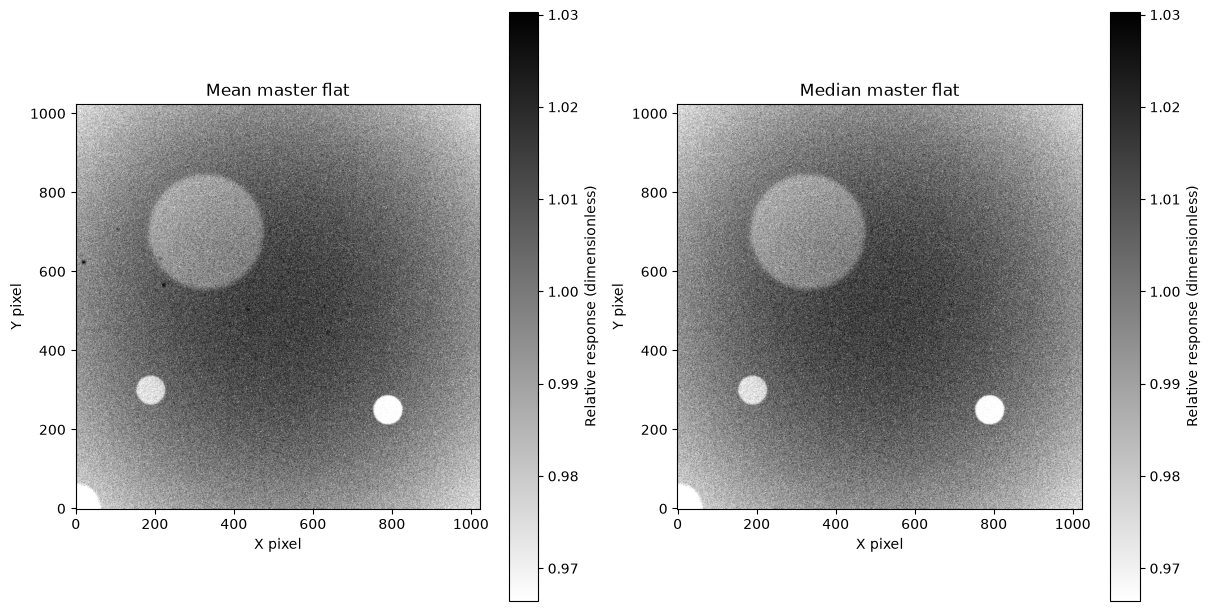

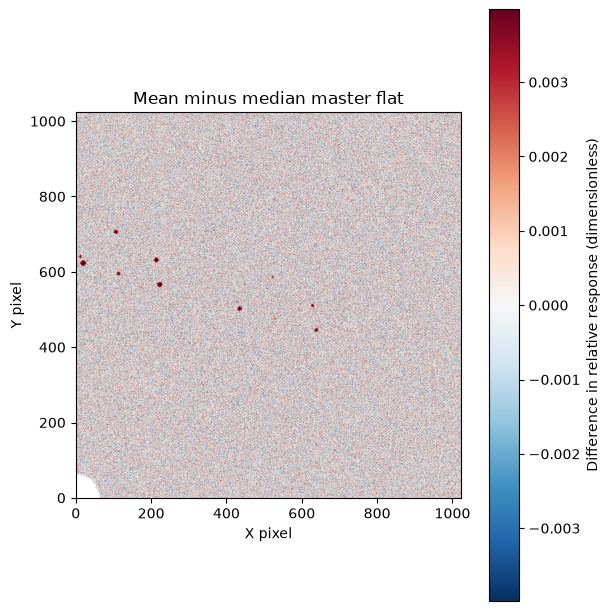

In [52]:
# Combine at each pixel, then normalize each master to a median of 1. Test mean and median normalizations
mean_flat = master_flat(kept_paths, master_bias_frame, dark_rate * gain, gain,
                        bad_pixel_mask, method='mean')
median_flat = master_flat(kept_paths, master_bias_frame, dark_rate * gain, gain,
                          bad_pixel_mask, method='median')

# Use the same display limits to compare the two master flats.
vmin, vmax = np.percentile(median_flat.compressed(), [1, 99])
fig, axs = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
for ax, flat, title in zip(axs, [mean_flat, median_flat], ['Mean master flat', 'Median master flat']):
    image = ax.imshow(flat, origin='lower', cmap='gray_r', vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel('X pixel')
    ax.set_ylabel('Y pixel')
    fig.colorbar(image, ax=ax, label='Relative response (dimensionless)')
plt.show()

difference = mean_flat - median_flat
limit = np.percentile(np.abs(difference.compressed()), 99)
fig, ax = plt.subplots(figsize=(6, 6), layout='constrained')
image = ax.imshow(difference, origin='lower', cmap='RdBu_r', vmin=-limit, vmax=limit)
ax.set_title('Mean minus median master flat')
ax.set_xlabel('X pixel')
ax.set_ylabel('Y pixel')
fig.colorbar(image, ax=ax, label='Difference in relative response (dimensionless)')
plt.show()


#### Written 2.2

The difference between the mean and median pixels come from the stars in the sky: as we can see in the left frame (mean), we have many dark spots corresponding to brighter regions, which likely correspond to stars in different frames. Meanwhile, because these stars move between frames, the median frame is able to get rid of these spots because for any given pixel, a star occurs there likely only once or twice --- an accident that biases the mean but not the median.

Therefore, it will be best to use the median frame from here on out. The tradeoff is that a median is less statistically efficient than a mean for Gaussian noise, so it generally has greater random uncertainty for the same number of frames. In exchange, it is less affected by stars that appear in only one or two frames.


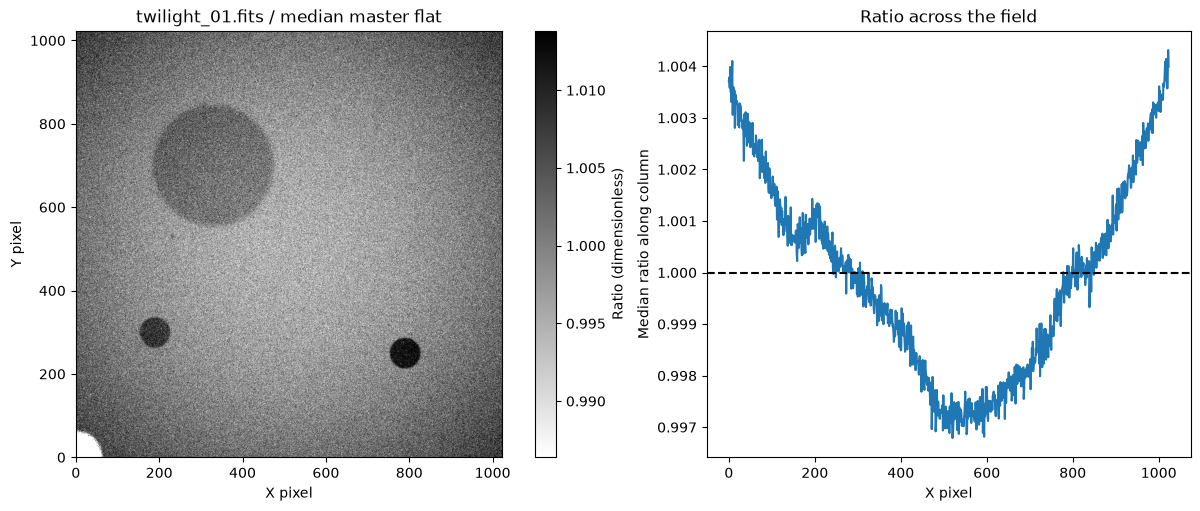

In [53]:
# Compare each rejected frame with the median master made only from kept frames.
selected_master_flat = median_flat
for path, frame, time, good in zip(twilight_frames, twilight_data, twilight_times, keep):
    if good:
        continue
    rejected_flat = calibrate_twilight(frame, time)
    rejected_flat /= np.ma.median(rejected_flat)
    ratio = rejected_flat / selected_master_flat

    fig, axs = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
    vmin, vmax = np.percentile(ratio.compressed(), [1, 99])
    image = axs[0].imshow(ratio, origin='lower', cmap='gray_r', vmin=vmin, vmax=vmax)
    axs[0].set_title(f'{path.name} / median master flat')
    axs[0].set_xlabel('X pixel')
    axs[0].set_ylabel('Y pixel')
    fig.colorbar(image, ax=axs[0], label='Ratio (dimensionless)')

    axs[1].plot(np.ma.median(ratio, axis=0))
    axs[1].axhline(1, color='black', linestyle='--')
    axs[1].set_xlabel('X pixel')
    axs[1].set_ylabel('Median ratio along column')
    axs[1].set_title('Ratio across the field')
    plt.show()


#### Written 2.3

Yes. The loss of linearity in the gain seems to decrease the brightness of the center of the rejected frame versus the centers of all other frames, which is what we predicted. The corners appear relatively brighter because they are less affected by this compression and the whole frame has been normalized to a median of one. The center-to-edge ratio therefore changes even though no extra light has reached the corners; this does not require spillover from nearly saturated pixels.


# Part 3

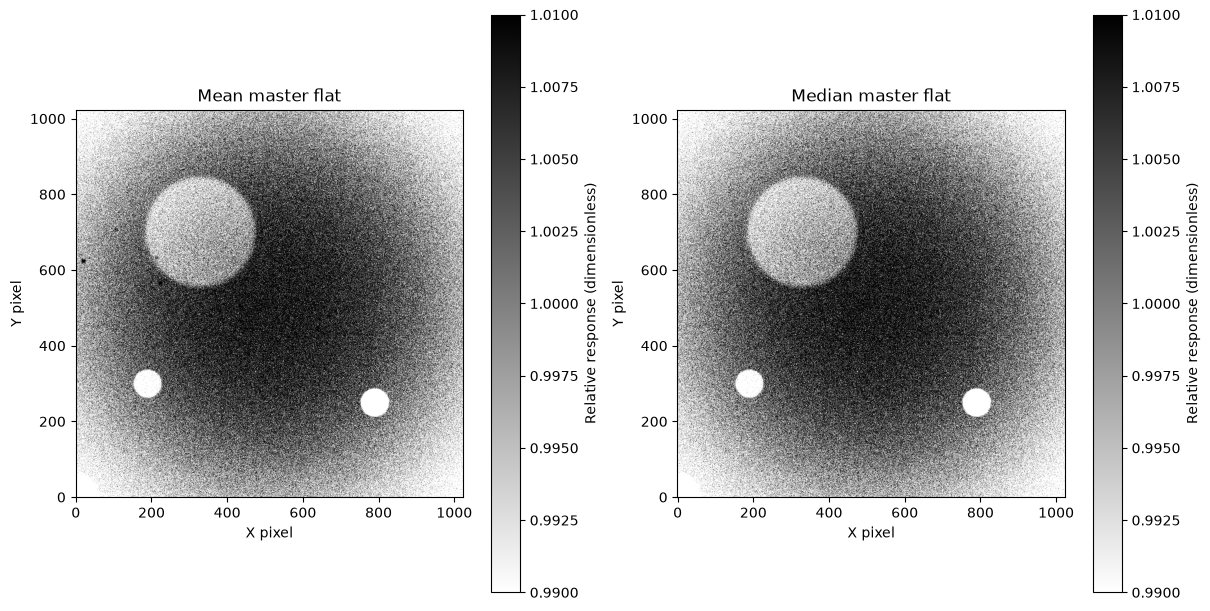

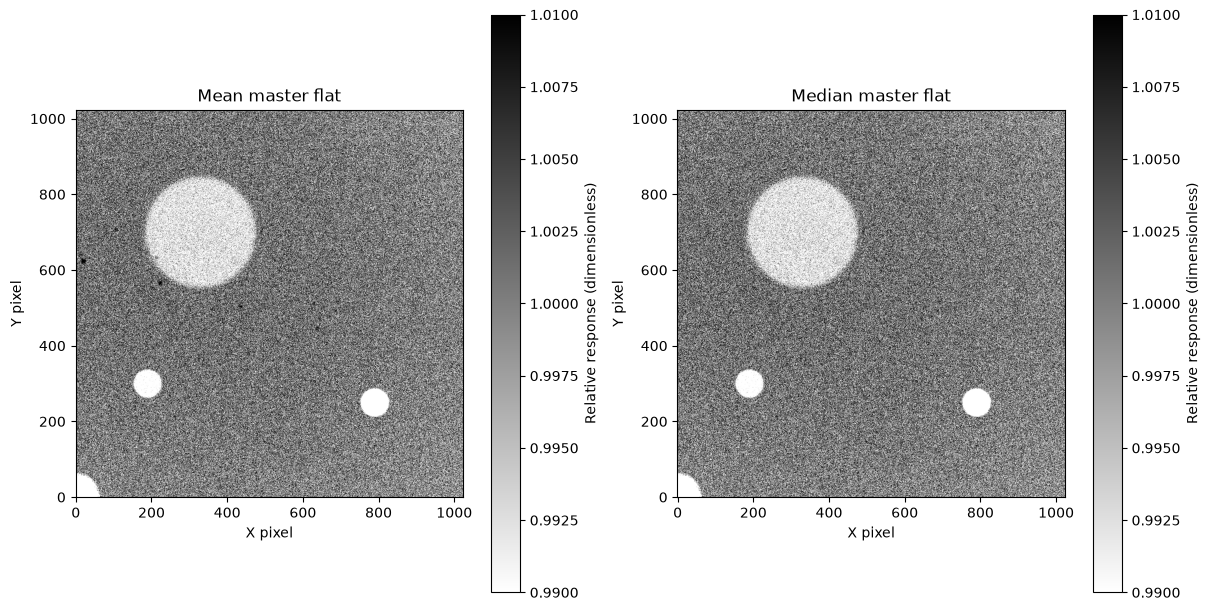

In [54]:
# Display flat with a stretch of a few percent either side of one
vmin, vmax = np.percentile(mean_flat.compressed(), [1, 99])
fig, axs = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
for ax, flat, title in zip(axs, [mean_flat, median_flat], ['Mean master flat', 'Median master flat']):
    image = ax.imshow(flat, origin='lower', cmap='gray_r', vmin=0.99, vmax=1.01)
    ax.set_title(title)
    ax.set_xlabel('X pixel')
    ax.set_ylabel('Y pixel')
    fig.colorbar(image, ax=ax, label='Relative response (dimensionless)')
plt.show()


# Take the vignetting out first (basically fitting a quadratic form over the flats)
def remove_vignetting(flat):
    y, x = np.indices(flat.shape, dtype=float)
    x = 2 * x / (flat.shape[1] - 1) - 1
    y = 2 * y / (flat.shape[0] - 1) - 1
    terms = np.stack([np.ones_like(x), x, y, x**2, x*y, y**2], axis=-1)
    samples = flat[::16, ::16]
    design = terms[::16, ::16].reshape(-1, 6)
    values = samples.data.ravel()
    valid = ~np.ma.getmaskarray(samples).ravel()
    good = valid.copy()
    for _ in range(5):
        coefficients = np.linalg.lstsq(design[good], values[good], rcond=None)[0]
        residual = values - design @ coefficients
        center = np.median(residual[good])
        scatter = 1.4826 * np.median(np.abs(residual[good] - center))
        good = valid & (np.abs(residual - center) < 3 * scatter)
    coefficients = np.linalg.lstsq(design[good], values[good], rcond=None)[0]
    vignetting = terms @ coefficients
    corrected = flat / vignetting
    return corrected / np.ma.median(corrected)

mean_flat = remove_vignetting(mean_flat)
median_flat = remove_vignetting(median_flat)




# Re-display
vmin, vmax = np.percentile(mean_flat.compressed(), [1, 99])
fig, axs = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
for ax, flat, title in zip(axs, [mean_flat, median_flat], ['Mean master flat', 'Median master flat']):
    image = ax.imshow(flat, origin='lower', cmap='gray_r', vmin=0.99, vmax=1.01)
    ax.set_title(title)
    ax.set_xlabel('X pixel')
    ax.set_ylabel('Y pixel')
    fig.colorbar(image, ax=ax, label='Relative response (dimensionless)')
plt.show()

#### 3.1 Written (dust blob locations)

We see three measurable dust blobs: one very large one around (300, 700), one around (200, 300), and one around (800, 250). There is also a feature at the bottom left (around 0,0), but it is clipped by the image boundary and its central pixels are masked. We cannot reliably measure its center or depth or establish that it is another dust blob from the masked flat alone.


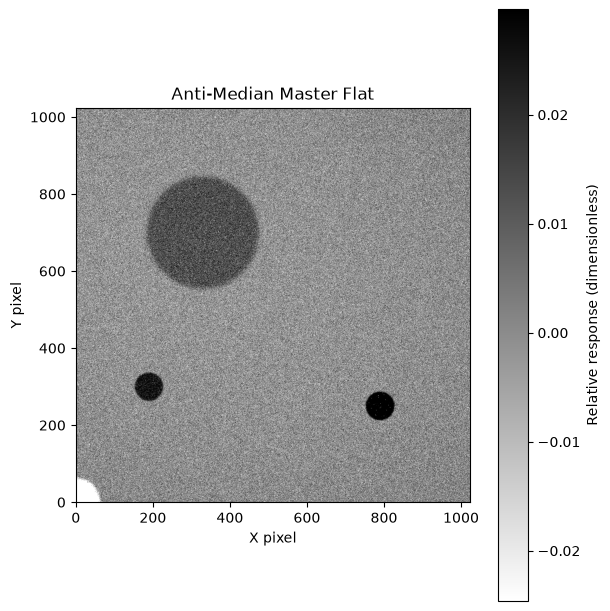

In [55]:
# turn median flat into 1 - median flat
reversed_median_flat = 1 - median_flat

# show this new "anti-median" flat
vmin, vmax = np.percentile(reversed_median_flat.compressed(), [1, 99])
fig, ax = plt.subplots(figsize=(6, 6), layout='constrained')
image = ax.imshow(reversed_median_flat, origin='lower', cmap='gray_r', vmin=vmin, vmax=vmax)
ax.set_title('Anti-Median Master Flat')
ax.set_xlabel('X pixel')
ax.set_ylabel('Y pixel')
fig.colorbar(image, ax=ax, label='Relative response (dimensionless)')
plt.show()

[334.93628597] [702.46523911]
[189.98009922] [299.72106844]
[790.2289266] [250.00984509]
[nan] [nan]


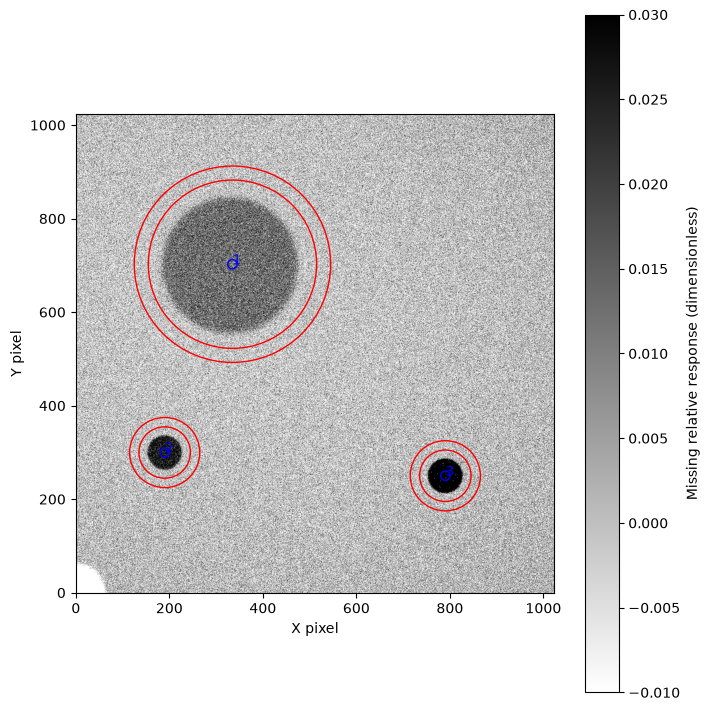

blob x_pixel  y_pixel  depth  fraction_removed percent_removed
---- -------- -------- ------ ---------------- ---------------
   1 334.9363 702.4652 0.0142           0.0141          1.4140
   2 189.9801 299.7211 0.0305           0.0305          3.0478
   3 790.2289 250.0098 0.0498           0.0498          4.9792
Blob 4: center and central depth unavailable; the corner is clipped and its core is masked.


In [56]:
# Measure the blobs with the centroiding and aperture photometry from the in-class aperture photometry notebook. 

# CENTROIDING

from photutils.centroids import centroid_2dg, centroid_sources

# Start with an initial guess (from visual inspection or some other image/process).
# The search box has to hold the whole ~42 pixel trail of the comparison star,
# otherwise the centroid gets pulled toward whichever end of the trail is inside it.

x_center_target_1, y_center_target_1 = centroid_sources(reversed_median_flat, 310, 700, box_size=351,
                        mask=np.ma.getmaskarray(reversed_median_flat), centroid_func=centroid_2dg)

x_center_target_2, y_center_target_2 = centroid_sources(reversed_median_flat, 190, 300, box_size=151,
                        mask=np.ma.getmaskarray(reversed_median_flat), centroid_func=centroid_2dg)

x_center_target_3, y_center_target_3 = centroid_sources(reversed_median_flat, 800, 250, box_size=151,
                        mask=np.ma.getmaskarray(reversed_median_flat), centroid_func=centroid_2dg)

x_center_target_4, y_center_target_4 = np.array([np.nan]), np.array([np.nan])

print(x_center_target_1, y_center_target_1)
print(x_center_target_2, y_center_target_2)
print(x_center_target_3, y_center_target_3)
print(x_center_target_4, y_center_target_4)



# Find each blob's center with centroid_sources,

from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
from astropy.table import Table

coordinates = [(x[0], y[0]) for x, y in [
    (x_center_target_1, y_center_target_1),
    (x_center_target_2, y_center_target_2),
    (x_center_target_3, y_center_target_3)]]
annulus_radii = [(180, 210), (55, 75), (55, 75)]
blob_measurements = Table(names=['blob', 'x_pixel', 'y_pixel', 'depth', 'fraction_removed'],
                          dtype=[int, float, float, float, float])

fig, ax = plt.subplots(figsize=(7, 7), layout='constrained')
image = ax.imshow(reversed_median_flat, origin='lower', cmap='gray_r', vmin=-0.01, vmax=0.03)
for i, (position, (r_in, r_out)) in enumerate(zip(coordinates, annulus_radii), start=1):
    aperture = CircularAperture(position, r=10)
    annulus = CircularAnnulus(position, r_in=r_in, r_out=r_out)
    aperture.plot(ax=ax, color='blue')
    annulus.plot(ax=ax, color='red')
    ax.text(*position, str(i), color='blue')
ax.set_xlabel('X pixel')
ax.set_ylabel('Y pixel')
fig.colorbar(image, ax=ax, label='Missing relative response (dimensionless)')
plt.show()







# its depth, (the fraction of the light it removes at its center, from the mean in a small aperture at the center compared with the mean in an annulus of clean flat outside it)


for i, (position, (r_in, r_out)) in enumerate(zip(coordinates, annulus_radii), start=1):
    aperture = CircularAperture(position, r=10)
    annulus = CircularAnnulus(position, r_in=r_in, r_out=r_out)
    mask = np.ma.getmaskarray(reversed_median_flat)
    phot_table = aperture_photometry(reversed_median_flat.data, [aperture, annulus], mask=mask)
    aperture_area = aperture.area_overlap(reversed_median_flat.data, mask=mask)
    annulus_area = annulus.area_overlap(reversed_median_flat.data, mask=mask)
    center_mean = phot_table['aperture_sum_0'][0] / aperture_area
    bkg_mean = phot_table['aperture_sum_1'][0] / annulus_area
    depth = center_mean - bkg_mean
    fraction_removed = depth / (1 - bkg_mean)
    blob_measurements.add_row([i, *position, depth, fraction_removed])



blob_measurements['percent_removed'] = 100 * blob_measurements['fraction_removed']
for name in blob_measurements.colnames[1:]:
    blob_measurements[name].info.format = '.4f'
print(blob_measurements)
print('Blob 4: center and central depth unavailable; the corner is clipped and its core is masked.')






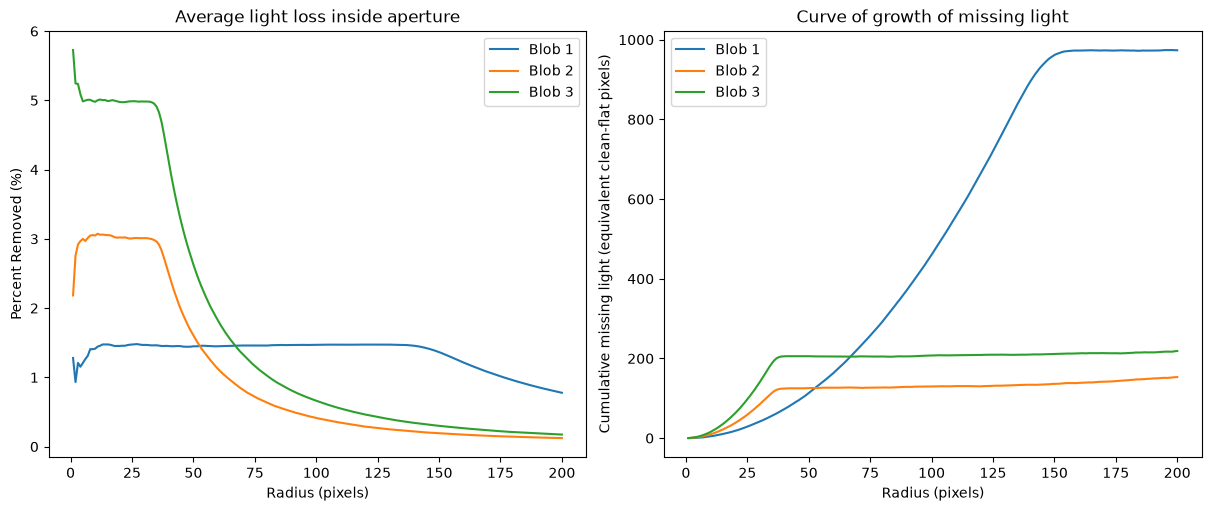

blob total_missing_light diameter_pixels
---- ------------------- ---------------
   1              972.97          295.99
   2              128.52           73.27
   3              205.30           72.45


In [57]:
# Now build a curve of growth of the missing light:

growth_measurements = Table(names=['blob', 'radius', 'depth', 'fraction_removed', 'percent_removed', 'missing_light'],
                            dtype=[int, int, float, float, float, float])

for radius in range(1, 201):
    for i, (position, (r_in, r_out)) in enumerate(zip(coordinates, annulus_radii), start=1):
        aperture = CircularAperture(position, r=radius)
        annulus = CircularAnnulus(position, r_in=r_in, r_out=r_out)
        mask = np.ma.getmaskarray(reversed_median_flat)
        phot_table = aperture_photometry(reversed_median_flat.data, [aperture, annulus], mask=mask)
        aperture_area = aperture.area_overlap(reversed_median_flat.data, mask=mask)
        annulus_area = annulus.area_overlap(reversed_median_flat.data, mask=mask)
        center_mean = phot_table['aperture_sum_0'][0] / aperture_area
        bkg_mean = phot_table['aperture_sum_1'][0] / annulus_area
        depth = center_mean - bkg_mean
        fraction_removed = depth / (1 - bkg_mean)
        missing_light = (phot_table['aperture_sum_0'][0] - bkg_mean * aperture_area) / (1 - bkg_mean)
        growth_measurements.add_row([i, radius, depth, fraction_removed, 100 * fraction_removed, missing_light])


# show a graph of percent removed vs radius from 1 to 200 for each blob

import matplotlib.pyplot as plt

fig, (ax, ax_growth) = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for i in range(1, 4):
    rows = growth_measurements[growth_measurements['blob'] == i]
    ax.plot(rows['radius'], rows['percent_removed'], label=f'Blob {i}')
    ax_growth.plot(rows['radius'], rows['missing_light'], label=f'Blob {i}')
ax.set_xlabel('Radius (pixels)')
ax.set_ylabel('Percent Removed (%)')
ax.set_title('Average light loss inside aperture')
ax.legend()
ax_growth.set_xlabel('Radius (pixels)')
ax_growth.set_ylabel('Cumulative missing light (equivalent clean-flat pixels)')
ax_growth.set_title('Curve of growth of missing light')
ax_growth.legend()
plt.show()

blob_sizes = Table(names=['blob', 'total_missing_light', 'diameter_pixels'], dtype=[int, float, float])
plateau_ranges = [(170, 200), (80, 100), (80, 100)]
for i, (r_min, r_max) in enumerate(plateau_ranges, start=1):
    rows = growth_measurements[(growth_measurements['blob'] == i)
                               & (growth_measurements['radius'] >= r_min)
                               & (growth_measurements['radius'] <= r_max)]
    total_missing = np.median(rows['missing_light'])
    depth = blob_measurements['fraction_removed'][i - 1]
    diameter = 2 * np.sqrt(total_missing / (np.pi * depth))
    blob_sizes.add_row([i, total_missing, diameter])
for name in blob_sizes.colnames[1:]:
    blob_sizes[name].info.format = '.2f'
print(blob_sizes)

#### 3.3 Written

The cumulative missing-light curves grow as the aperture includes more of each dust shadow, then level off once the aperture encloses the whole blob. For an approximately uniform central deficit, the initial rise is roughly proportional to aperture area ($r^2$). Adding clean background outside the blob adds almost no missing light, so the integrated curve reaches a plateau rather than decreasing. Small residual trends reflect noise or imperfect background removal.

Approximating each blob as a circular shadow of fractional depth $d$, the total missing light is $L_\infty \simeq d\pi(D/2)^2$, giving $D \simeq 2\sqrt{L_\infty/(\pi d)}$. These are equivalent circular diameters, not exact edge measurements. The code estimates the plateau over radii 170–200 pixels for the large blob and 80–100 pixels for the two smaller blobs.

The plateau totals are approximately 973.0, 128.5, and 205.3 equivalent full-pixels (i.e. that many pixels, if each pixel were $1$ in brightness). Together with the measured central depths, these give diameters of approximately **296 pixels** for blob 1 (large upper-left shadow), **73 pixels** for blob 2 (lower-left shadow), and **72 pixels** for blob 3 (lower-right shadow). The clipped, masked corner feature is not measurable by this method.


#### 3.4 Written

The smaller blobs come from dust closest to the sensor, because nearby dust casts a smaller, more sharply defined shadow. The two compact blobs have similar measured diameters, so these measurements do not confidently distinguish which is closer. The large blob in the top left comes from dust farther from the sensor. Its position within the image does not determine the distance of the dust from the sensor.

I am admittedly not entirely sure which of the two smaller blobs is the actual closest to the center; however, I believe that it is likely Blob 3 (described above) which is the closest to the sensor because it produces the smallest and deepest shadow. However, the measured diameters of blobs 2 and 3 are nearly identical, so their relative distances cannot be determined confidently from size alone.


### Part 4

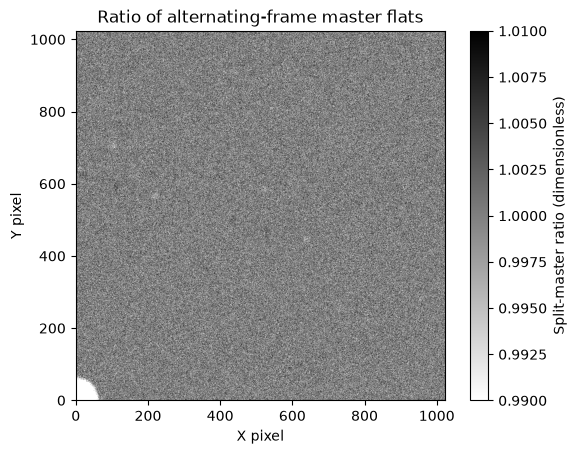

In [58]:
# split the kept frames into two lists (alternating)
kept_frames_1 = kept_paths[::2]
kept_frames_2 = kept_paths[1::2]

# create a master for both
master_1 = master_flat(kept_frames_1, master_bias_frame, dark_rate * gain, gain, bad_pixel_mask)
master_2 = master_flat(kept_frames_2, master_bias_frame, dark_rate * gain, gain, bad_pixel_mask)

# Divide the two masters to create a flat field
flat_field = master_1 / master_2

# display flat_field
import matplotlib.pyplot as plt

plt.imshow(flat_field, cmap='gray_r', origin='lower', vmin=0.99, vmax=1.01)
plt.colorbar(label='Split-master ratio (dimensionless)')
plt.title('Ratio of alternating-frame master flats')
plt.xlabel('X pixel')
plt.ylabel('Y pixel')
plt.show()


In [59]:
# standard deviation of flat_field
flat_field_std = np.ma.std(flat_field)
print(f'Standard Deviation of Flat Field: {flat_field_std:.4f}')

print(f"The noise in our full master is about half of the standard deviation we calculated above: {flat_field_std / 2:.4f}")

Standard Deviation of Flat Field: 0.0047
The noise in our full master is about half of the standard deviation we calculated above: 0.0024


#### 4.1 Written

The dust shadows and pixel-to-pixel response disappear because they are common to both half's masters and cancel when one is divided by the other. Noise and residual stars differ between the halves, so they remain in the ratio. The halves contain five and four frames, respectively; using half the ratio's standard deviation for the full-master noise is therefore an approximate estimate.

The ratio's pixel standard deviation is **0.00472**, so the estimated full-master pixel noise is **0.00236** (approximately **0.236%**).


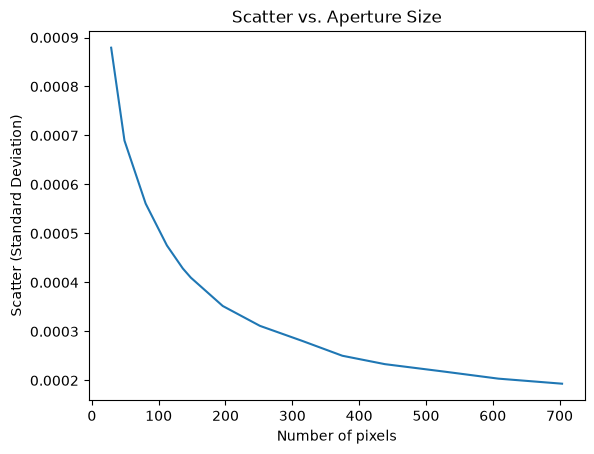

6.5-pixel aperture ratio scatter: 0.000428
Full-master fractional error: 0.000214 (0.0214%)
Poisson fractional error for 1e6 electrons: 0.001000
Full-master magnitude error: 0.000233 mag; project target: 0.5 mag


In [60]:
# for aperatures of radius 3 to 15:
# Place a few hundred circular apertures at random positions on the ratio image, record the mean inside each, and measure the scatter of those means.

aperture_radii = np.sort(np.append(np.arange(3, 16), 6.5))
num_apertures = 500
mean_values = []
scatter_values = []
pixel_counts = []
rng = np.random.default_rng(410)
positions = rng.integers(15, [flat_field.shape[1] - 15, flat_field.shape[0] - 15],
                        size=(num_apertures, 2))
y_indices, x_indices = np.ogrid[:flat_field.shape[0], :flat_field.shape[1]]

for radius in aperture_radii:
    means = []
    counts = []
    for _ in range(num_apertures):
        # Random position
        x, y = positions[_]
        # Create a circular aperture
        mask = (x_indices - x) ** 2 + (y_indices - y) ** 2 <= radius ** 2
        # Record the mean inside the aperture
        values = flat_field[mask]
        if values.count() == 0:
            continue
        means.append(values.mean())
        counts.append(values.count())
    mean_values.append(np.mean(means))
    scatter_values.append(np.std(means))
    pixel_counts.append(np.mean(counts))

# plot scatter (y axis) vs. number of pixels (x axis)
plt.plot(pixel_counts, scatter_values)
plt.xlabel('Number of pixels')
plt.ylabel('Scatter (Standard Deviation)')
plt.title('Scatter vs. Aperture Size')
plt.show()

star_index = np.flatnonzero(aperture_radii == 6.5)[0]
ratio_star_scatter = scatter_values[star_index] / mean_values[star_index]
full_star_error = ratio_star_scatter / 2
poisson_error = 1 / np.sqrt(1e6)
flat_error_mag = 2.5 / np.log(10) * full_star_error
print(f'6.5-pixel aperture ratio scatter: {ratio_star_scatter:.6f}')
print(f'Full-master fractional error: {full_star_error:.6f} ({100 * full_star_error:.4f}%)')
print(f'Poisson fractional error for 1e6 electrons: {poisson_error:.6f}')
print(f'Full-master magnitude error: {flat_error_mag:.6f} mag; project target: 0.5 mag')


#### 4.2 Written

As the number of usable pixels included in an aperture increases, the scatter of its mean generally decreases. For independent pixel noise with standard deviation $\sigma$, the uncertainty of the mean scales as $\sigma/\sqrt{N}$. Thus averaging over larger apertures reduces random flat noise. Correlated residuals, residual stars, and finite sampling can cause departures from this trend. The horizontal axis counts usable, unmasked pixels; aperture centers are kept far enough from the boundary to contain the complete aperture.


#### 4.3 Written

For an aperture of radius 6.5 pixels, the fractional scatter of means in the ratio is **0.000428**. The full master contributes about half of this: **0.000214**, or **0.0214%**, equivalent to **0.000233 mag**.

For a star yielding $10^6$ electrons, the Poisson uncertainty is $\sqrt{10^6}=1000$ electrons, a relative error of **0.001** (0.1%). The flat's random contribution here is about **0.21 times** this Poisson error. It is therefore a smaller contribution, rather than the dominant source of error.

My project measures galaxy color profiles and targets an accuracy of 0.5 mag in g'-r' at $2R_e$, with an i' correction for dust. For the stellar aperture tested here, the estimated random flat error is much smaller than this target and is below the Poisson error. This does not establish the error for faint galaxy surface brightness: sky subtraction and coherent large-scale flat errors may still be important near $2R_e$ and should be considered separately. Personally, due to the delicate nature of diffuse galactic light, I think it will be necessary to be careful about flat noise.


# AI Use Statement

I used AI in this problem set for the following tasks:

1. Help with importing frames from files.
2. Help with plotting libraries.
3. Writing coherent and efficient print statements in given cells.
4. Determining if particular functions existed in numpy or astropy or matplotlib libraries, and quickly referencing the documentation of these functions.
